In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
%matplotlib inline
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [4]:
df = pd.read_csv("Titanic-Dataset.csv")      # Titanic (Kaggle train.csv) - keep it in the same folder as this notebook
print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()
print(df.isnull().sum())

Rows: 891  Columns: 12
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Observations used: 714


,count,mean,std,min,25%,50%,75%,max
Fare,714.0,34.694514,52.918930,0.00,8.050,15.7417,33.375,512.3292
Age,714.0,29.699118,14.526497,0.42,20.125,28.0000,38.000,80.0000
Pclass,714.0,2.236695,0.838250,1.00,1.000,2.0000,3.000,3.0000
SibSp,714.0,0.512605,0.929783,0.00,0.000,0.0000,1.000,5.0000
Parch,714.0,0.431373,0.853289,0.00,0.000,0.0000,1.000,6.0000


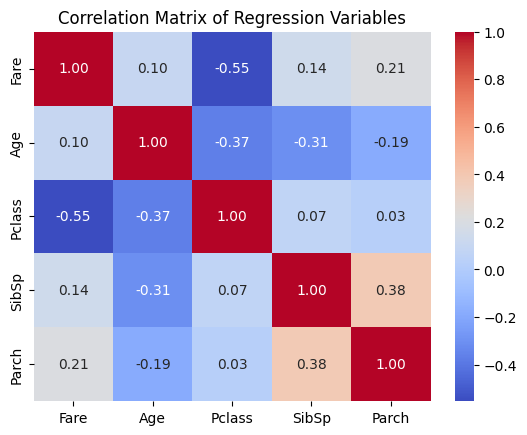

In [5]:
target = "Fare"
predictors = ["Age", "Pclass", "SibSp", "Parch"]
reg_df = df[[target] + predictors].dropna().copy()
print("Observations used:", len(reg_df))
display(reg_df.describe().T)
sns.heatmap(reg_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Regression Variables"); plt.show()

In [6]:
X, y = reg_df[predictors], reg_df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training:", len(X_train), " Testing:", len(X_test))
model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model.summary())
coefficients = pd.DataFrame({"Coefficient": model.params, "Std Error": model.bse,
                             "t-statistic": model.tvalues, "p-value": model.pvalues})
coefficients.round(4)

Training: 571  Testing: 143
                            OLS Regression Results                            
Dep. Variable:                   Fare   R-squared:                       0.447
Model:                            OLS   Adj. R-squared:                  0.443
Method:                 Least Squares   F-statistic:                     114.3
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           2.24e-71
Time:                        19:16:16   Log-Likelihood:                -2869.6
No. Observations:                 571   AIC:                             5749.
Df Residuals:                     566   BIC:                             5771.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        114.3043   

,Coefficient,Std Error,t-statistic,p-value
const,114.3043,7.0921,16.1172,0.0000
Age,-0.1766,0.1185,-1.4908,0.1366
Pclass,-37.1033,1.9917,-18.6290,0.0000
SibSp,6.6000,1.9368,3.4078,0.0007
Parch,12.1571,1.9184,6.3371,0.0000


Training R2 = 0.4468, Adjusted R2 = 0.4428
Test R2 = 0.1774, RMSE = 58.5198, MAE = 25.1817


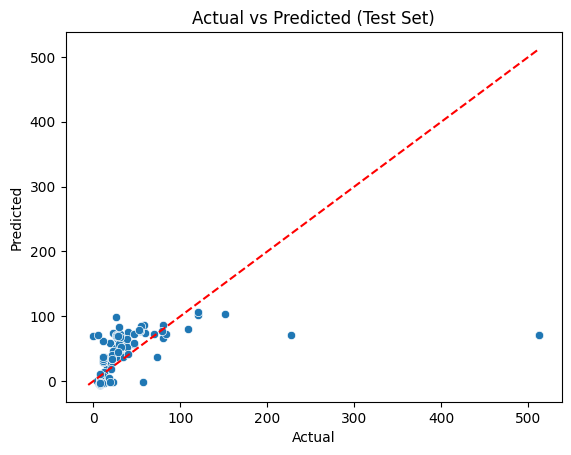

In [7]:
y_pred = model.predict(sm.add_constant(X_test))
mse = mean_squared_error(y_test, y_pred)
rmse, mae = np.sqrt(mse), mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
print(f"Training R2 = {model.rsquared:.4f}, Adjusted R2 = {model.rsquared_adj:.4f}")
print(f"Test R2 = {test_r2:.4f}, RMSE = {rmse:.4f}, MAE = {mae:.4f}")
sns.scatterplot(x=y_test, y=y_pred)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--"); plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title("Actual vs Predicted (Test Set)"); plt.show()

,Variable,VIF
1,Age,1.267
2,Pclass,1.161
3,SibSp,1.218
4,Parch,1.152


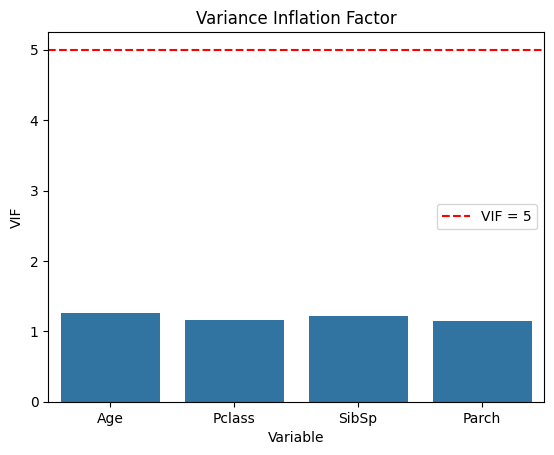

In [8]:
X_vif = sm.add_constant(X_train)
vif = pd.DataFrame({"Variable": X_vif.columns,
                    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
vif = vif[vif["Variable"] != "const"]
display(vif.round(3))
sns.barplot(data=vif, x="Variable", y="VIF"); plt.axhline(5, color="red", linestyle="--", label="VIF = 5")
plt.title("Variance Inflation Factor"); plt.legend(); plt.show()

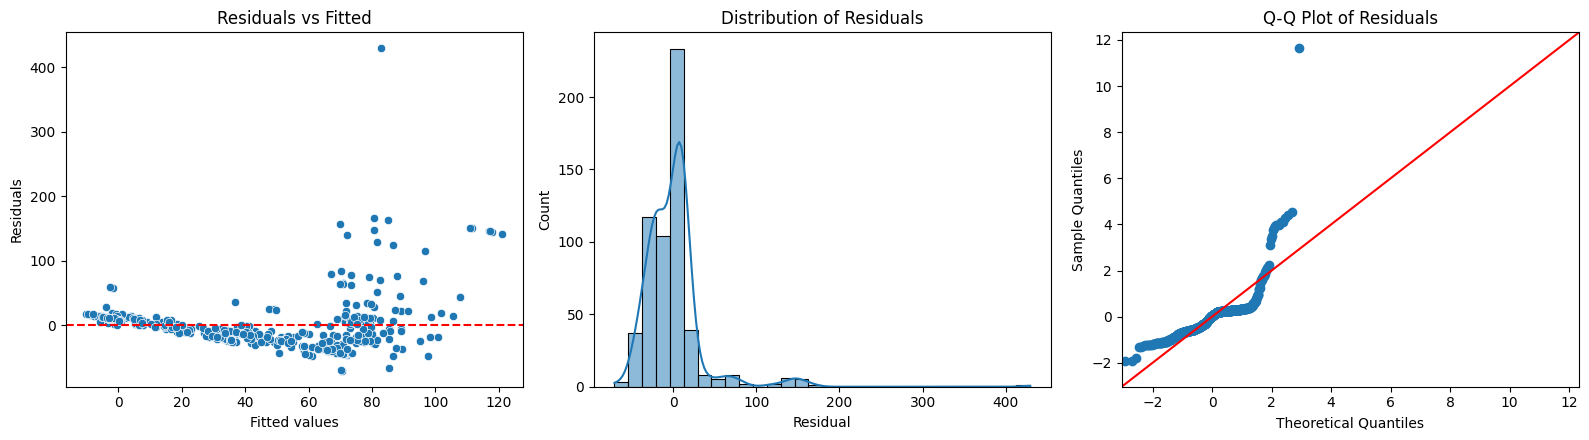

In [9]:
fitted, residuals = model.fittedvalues, model.resid
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(x=fitted, y=residuals, ax=axes[0]); axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs Fitted")
sns.histplot(residuals, bins=30, kde=True, ax=axes[1]); axes[1].set(xlabel="Residual", title="Distribution of Residuals")
sm.qqplot(residuals, line="45", fit=True, ax=axes[2]); axes[2].set_title("Q-Q Plot of Residuals")
plt.tight_layout(); plt.show()

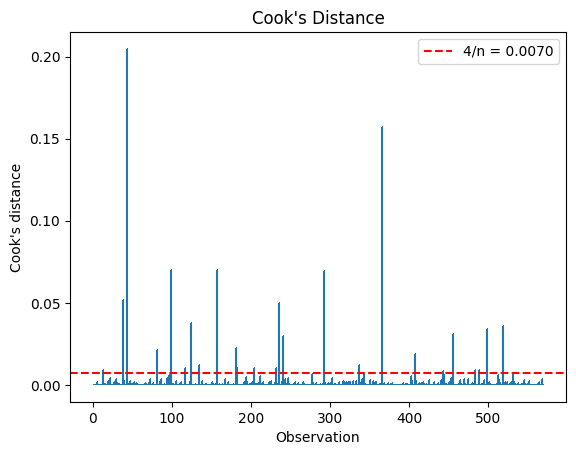

Potentially influential observations: 25


,Age,Pclass,SibSp,Parch,Actual,Fitted,Residual,Std. Residual,Cook's D
679,36.0,1,0,1,512.3292,83.000469,429.328731,11.645666,0.204708
438,64.0,1,1,4,263.0000,121.127035,141.872965,3.930067,0.156904
27,19.0,1,3,2,263.0000,117.959980,145.040020,3.963063,0.070230
341,24.0,1,3,2,263.0000,117.076966,145.923034,3.986383,0.069742
88,23.0,1,3,2,263.0000,117.253568,145.746432,3.981636,0.069703
311,18.0,1,2,2,262.3750,111.536540,150.838460,4.107455,0.051970
742,21.0,1,2,2,262.3750,111.006731,151.368269,4.120610,0.050175
118,24.0,1,0,1,247.5208,85.119703,162.401097,4.409999,0.037939
299,50.0,1,0,1,247.5208,80.528029,166.992771,4.532467,0.036018
700,18.0,1,1,0,227.5250,80.622228,146.902772,3.990881,0.033875


In [10]:
influence = OLSInfluence(model)
diagnostics = pd.DataFrame({"Actual": y_train, "Fitted": fitted, "Residual": residuals,
                            "Std. Residual": influence.resid_studentized_internal,
                            "Cook's D": influence.cooks_distance[0]})
n = len(X_train)
threshold = 4 / n
plt.stem(np.arange(n), diagnostics["Cook's D"], markerfmt=",", basefmt=" ")
plt.axhline(threshold, color="red", linestyle="--", label=f"4/n = {threshold:.4f}")
plt.xlabel("Observation"); plt.ylabel("Cook's distance"); plt.title("Cook's Distance"); plt.legend(); plt.show()
influential = diagnostics[diagnostics["Cook's D"] > threshold]
print("Potentially influential observations:", len(influential))
X_train.loc[influential.index].join(influential).sort_values("Cook's D", ascending=False).head(10)

In [11]:
summary = pd.DataFrame({
    "Metric": ["Training R2","Adjusted R2","Test R2","Test MSE","Test RMSE","Test MAE","Maximum VIF","Influential observations"],
    "Value": [model.rsquared, model.rsquared_adj, test_r2, mse, rmse, mae, vif["VIF"].max(), len(influential)]})
display(summary)
coefficients.to_csv("regression_coefficients.csv"); vif.to_csv("vif_results.csv", index=False)
diagnostics.to_csv("regression_diagnostics.csv"); summary.to_csv("regression_summary.csv", index=False)

,Metric,Value
0,Training R2,0.446754
1,Adjusted R2,0.442844
2,Test R2,0.177437
3,Test MSE,3424.568518
4,Test RMSE,58.519813
5,Test MAE,25.181679
6,Maximum VIF,1.267303
7,Influential observations,25.000000
